In [1]:
import numpy as np
import matplotlib.pyplot as plt

Lx = 1.0
u_bottom, u_top = 0.0, 2.0


def f(x):
    return -np.pi**2 * np.sin(np.pi * x)

 
def u_ref(x):
    return np.sin(np.pi * x) + 2 * x

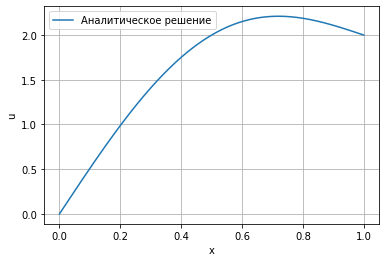

In [2]:
x_ref = np.linspace(0, Lx, 300)
plt.plot(x_ref, u_ref(x_ref), label="Аналитическое решение")
# plt.scatter(x, u, label="МКР", color="red")
plt.xlabel("x")
plt.ylabel("u")
plt.legend()
plt.grid()
plt.show()


In [4]:
def poisson_fem(dx):
    Nx = int(round(Lx/dx))
    x = np.linspace(0, Lx, Nx+1)
    K = np.zeros((Nx+1, Nx+1))
    S = np.zeros(Nx+1)
    for e in range(Nx):
        he = x[e+1] - x[e]
        fe = (f(x[e+1]) + f(x[e])) / 2
        Ke = np.array([[-1,1],[1,-1]])/he
        Se = np.array([1,1])*fe*he/2
        K[e:e+2,e:e+2] += Ke
        S[e:e+2] += Se
    V = np.empty(Nx+1)
    V[0], V[-1] = u_bottom, u_top
    
    A = K[1:-1,1:-1]
    b = S[1:-1] - K[0, 1:-1]* u_bottom - K[-1, 1:-1]*u_top
    
    V[1:-1] = np.linalg.solve(A,b)
    
    return x, V
        

In [9]:
def solve_poisson(dx):
    """
    Решает u'' = f(x) на [0, Lx] с условиями Дирихле
    u(0) = u_bottom, u(Lx) = u_top методом конечных разностей.

    В данном случае функция принимает шаг сетки dx и возвращает численное решение u на сетке x.
    """
    Nx = int(round(Lx / dx))      # число интервалов

    x = np.linspace(0, Lx, Nx + 1)
    dx = Lx / Nx                  # фактический шаг сетки

    # Матрица для внутренних узлов (размер Nx-1)
    n = Nx - 1
    A = (np.diag(-2 * np.ones(n))
         + np.diag(np.ones(n - 1), 1)
         + np.diag(np.ones(n - 1), -1))

    # Правая часть с учётом граничных условий
    b = f(x[1:-1]) * dx**2
    b[0] -= u_bottom 
    b[-1] -= u_top

    # Решение СЛАУ
    u = np.empty(Nx + 1)
    u[0], u[-1] = u_bottom, u_top
    u[1:-1] = np.linalg.solve(A, b)
    return x, u

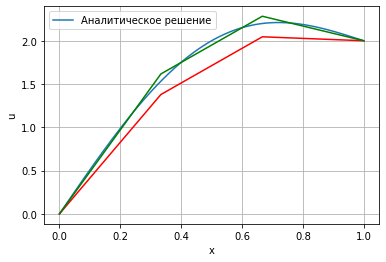

In [12]:
x, V = poisson_fem(0.3)
x_mkr, V_mkr = solve_poisson(0.3)

x_ref = np.linspace(0, Lx, 300)
plt.plot(x_ref, u_ref(x_ref), label="Аналитическое решение")
plt.plot(x,V, color = "red")
plt.plot(x_mkr,V_mkr, color = "green")
plt.xlabel("x")
plt.ylabel("u")
plt.legend()
plt.grid()
plt.show()